
### Just run it. Script will automatically download the dataset from Hugging face

How to run (Section 1 — Phishing Email Detection)
Open this notebook in Google Colab.
Runtime → Change runtime type → GPU (optional, speeds up the LSTM) — a standard runtime is otherwise fine, since the dataset is only ~18,600 emails.
Run cells top to bottom (Runtime → Run all). No manual upload is needed — the dataset is pulled automatically from the Hugging Face Hub (zefang-liu/phishing-email-dataset).


In [ ]:
# Install/upgrade the libraries we need
!pip install -q datasets scikit-learn tensorflow nltk matplotlib seaborn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.9/572.9 MB 768.2 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 148.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 105.7 MB/s eta 0:00:00


In [ ]:
# Imports
import re
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_curve, auc, classification_report
)

import tensorflow as tf
from keras.preprocessing.text import Tokenizer
from keras.preprocessing.sequence import pad_sequences
from keras.models import Sequential
from keras.layers import Embedding, LSTM, Dense, Dropout, SpatialDropout1D
from keras.callbacks import EarlyStopping

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

sns.set_style("whitegrid")


/usr/local/lib/python3.13/dist-packages/jax/_src/cloud_tpu_init.py:86: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(


In [ ]:
# Load the dataset
raw = load_dataset("zefang-liu/phishing-email-dataset")
df = raw["train"].to_pandas()

# Standardise column names
df = df.rename(columns={"Email Text": "text", "Email Type": "label_text"})
df = df.dropna(subset=["text", "label_text"]).reset_index(drop=True)

# Binary label: 1 = Phishing Email, 0 = Safe Email
df["label"] = (df["label_text"].str.strip().str.lower() == "phishing email").astype(int)

print(f"Total emails: {len(df)}")
df.head()




README.md:   0%|          | 0.00/616 [00:00<?, ?B/s]

Phishing_Email.csv: reconstructing file:   0%|          |  0.00B / 52.0MB            

Phishing_Email.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/18650 [00:00<?, ? examples/s]

Total emails: 18634


,Unnamed: 0,text,label_text,label
0,0,"re : 6 . 1100 , disc : uniformitarianism , re ...",Safe Email,0
1,1,the other side of * galicismos * * galicismo *...,Safe Email,0
2,2,re : equistar deal tickets are you still avail...,Safe Email,0
3,3,\nHello I am your hot lil horny toy.\n I am...,Phishing Email,1
4,4,software at incredibly low prices ( 86 % lower...,Phishing Email,1


In [ ]:
#summary of Dataframe
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18634 entries, 0 to 18633
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  18634 non-null  int64 
 1   text        18634 non-null  object
 2   label_text  18634 non-null  object
 3   label       18634 non-null  int64 
dtypes: int64(2), object(2)
memory usage: 582.4+ KB


/tmp/ipykernel_2491/851907674.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="label_text", data=df, palette="Set2")


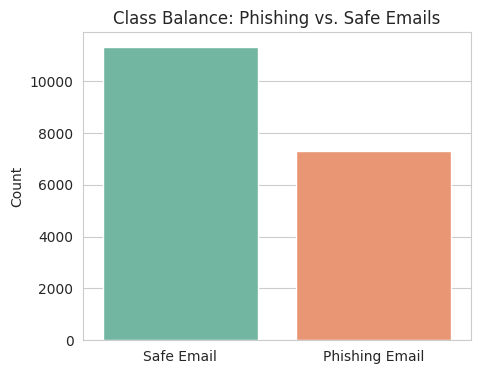

label_text
Safe Email        60.76 %
Phishing Email    39.24 %
Name: proportion, dtype: object


In [ ]:
# Class balance
plt.figure(figsize=(5, 4))
sns.countplot(x="label_text", data=df, palette="Set2")
plt.title("Class Balance: Phishing vs. Safe Emails")
plt.xlabel("")
plt.ylabel("Count")
plt.show()

print(df["label_text"].value_counts(normalize=True).mul(100).round(2).astype(str) + " %")


In [ ]:
# Text cleaning
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words("english"))

url_pattern = re.compile(r"http\S+|www\.\S+")
email_pattern = re.compile(r"\S+@\S+")
html_pattern = re.compile(r"<.*?>")
non_alpha_pattern = re.compile(r"[^a-z\s]")

def clean_text(text: str) -> str:
    text = str(text).lower()
    text = url_pattern.sub(" ", text)
    text = email_pattern.sub(" ", text)
    text = html_pattern.sub(" ", text)
    text = non_alpha_pattern.sub(" ", text)
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(t) for t in tokens if t not in stop_words and len(t) > 2]
    return " ".join(tokens)

df["clean_text"] = df["text"].apply(clean_text)
df = df[df["clean_text"].str.len() > 0].reset_index(drop=True)

df[["text", "clean_text", "label_text"]].head()


,text,clean_text,label_text
0,"re : 6 . 1100 , disc : uniformitarianism , re ...",disc uniformitarianism sex lang dick hudson ob...,Safe Email
1,the other side of * galicismos * * galicismo *...,side galicismos galicismo spanish term name im...,Safe Email
2,re : equistar deal tickets are you still avail...,equistar deal ticket still available assist ro...,Safe Email
3,\nHello I am your hot lil horny toy.\n I am...,hello hot lil horny toy one dream open minded ...,Phishing Email
4,software at incredibly low prices ( 86 % lower...,software incredibly low price lower drapery se...,Phishing Email


In [ ]:
# Train / test split
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["clean_text"], df["label"],
    test_size=0.2, random_state=SEED, stratify=df["label"]
)

print(f"Train size: {len(X_train_text)}  |  Test size: {len(X_test_text)}")


Train size: 14901  |  Test size: 3726


## Logistic Regression

In [ ]:
# TF-IDF vector
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(X_train_text)
X_test_tfidf = tfidf.transform(X_test_text)

# Train Logistic Regression
log_reg = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)
log_reg.fit(X_train_tfidf, y_train)

# Predictions
lr_preds = log_reg.predict(X_test_tfidf)
lr_probs = log_reg.predict_proba(X_test_tfidf)[:, 1]

lr_metrics = {
    "Accuracy": accuracy_score(y_test, lr_preds),
    "Precision": precision_score(y_test, lr_preds),
    "Recall": recall_score(y_test, lr_preds),
    "F1-score": f1_score(y_test, lr_preds),
}
print("Logistic Regression performance:")
for k, v in lr_metrics.items():
    print(f"  {k}: {v:.4f}")
print()
print(classification_report(y_test, lr_preds, target_names=["Safe", "Phishing"]))


Logistic Regression performance:
  Accuracy: 0.9670
  Precision: 0.9407
  Recall: 0.9774
  F1-score: 0.9587

              precision    recall  f1-score   support

        Safe       0.99      0.96      0.97      2265
    Phishing       0.94      0.98      0.96      1461

    accuracy                           0.97      3726
   macro avg       0.96      0.97      0.97      3726
weighted avg       0.97      0.97      0.97      3726



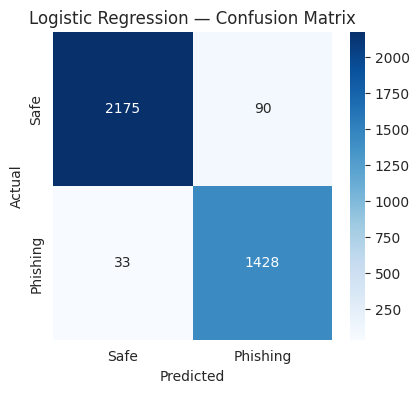

In [ ]:
# Logistic Regression - Confusion Matrix
cm_lr = confusion_matrix(y_test, lr_preds)
plt.figure(figsize=(4.5, 4))
sns.heatmap(cm_lr, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Safe", "Phishing"], yticklabels=["Safe", "Phishing"])
plt.title("Logistic Regression — Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


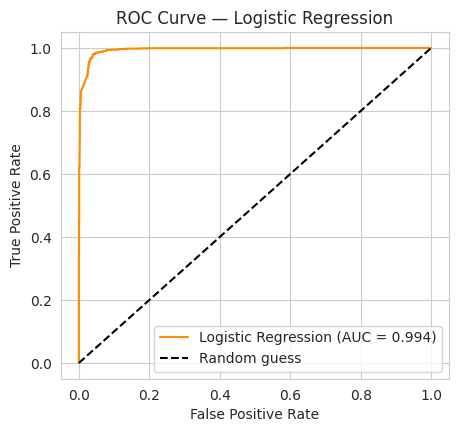

In [ ]:
# Logistic Regression - ROC Curve
fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_probs)
roc_auc_lr = auc(fpr_lr, tpr_lr)

plt.figure(figsize=(5, 4.5))
plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {roc_auc_lr:.3f})", color="darkorange")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Logistic Regression")
plt.legend(loc="lower right")
plt.show()


## LSTM

In [ ]:
# Tokenise and pad sequences for the LSTM
VOCAB_SIZE = 10000
MAX_LEN = 200
EMBEDDING_DIM = 100

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train_text)

X_train_seq = tokenizer.texts_to_sequences(X_train_text)
X_test_seq = tokenizer.texts_to_sequences(X_test_text)

X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding="post", truncating="post")
X_test_pad = pad_sequences(X_test_seq, maxlen=MAX_LEN, padding="post", truncating="post")

print("Padded training shape:", X_train_pad.shape)


Padded training shape: (14901, 200)


In [ ]:
# Build the LSTM model
lstm_model = Sequential([
    Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM, input_length=MAX_LEN),
    SpatialDropout1D(0.2),
    LSTM(64, dropout=0.2, recurrent_dropout=0.2),
    Dense(32, activation="relu"),
    Dropout(0.3),
    Dense(1, activation="sigmoid"),
])

lstm_model.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy"],
)
lstm_model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train the LSTM
early_stop = EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)

history = lstm_model.fit(
    X_train_pad, y_train,
    validation_split=0.1,
    epochs=8,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1,
)


Epoch 1/8
210/210 ━━━━━━━━━━━━━━━━━━━━ 26s 114ms/step - accuracy: 0.6240 - loss: 0.6306 - val_accuracy: 0.6968 - val_loss: 0.5306
Epoch 2/8
210/210 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - accuracy: 0.7807 - loss: 0.4964 - val_accuracy: 0.8256 - val_loss: 0.4384
Epoch 3/8
210/210 ━━━━━━━━━━━━━━━━━━━━ 23s 111ms/step - accuracy: 0.8072 - loss: 0.4741 - val_accuracy: 0.8464 - val_loss: 0.4164
Epoch 4/8
210/210 ━━━━━━━━━━━━━━━━━━━━ 23s 108ms/step - accuracy: 0.8356 - loss: 0.4235 - val_accuracy: 0.8659 - val_loss: 0.3741
Epoch 5/8
210/210 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - accuracy: 0.8561 - loss: 0.3999 - val_accuracy: 0.8679 - val_loss: 0.3660
Epoch 6/8
210/210 ━━━━━━━━━━━━━━━━━━━━ 23s 110ms/step - accuracy: 0.8657 - loss: 0.3295 - val_accuracy: 0.9296 - val_loss: 0.2394
Epoch 7/8
210/210 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - accuracy: 0.9406 - loss: 0.1881 - val_accuracy: 0.9477 - val_loss: 0.1361
Epoch 8/8
210/210 ━━━━━━━━━━━━━━━━━━━━ 23s 108ms/step - accuracy: 0.9621 - loss: 0.1154 - 

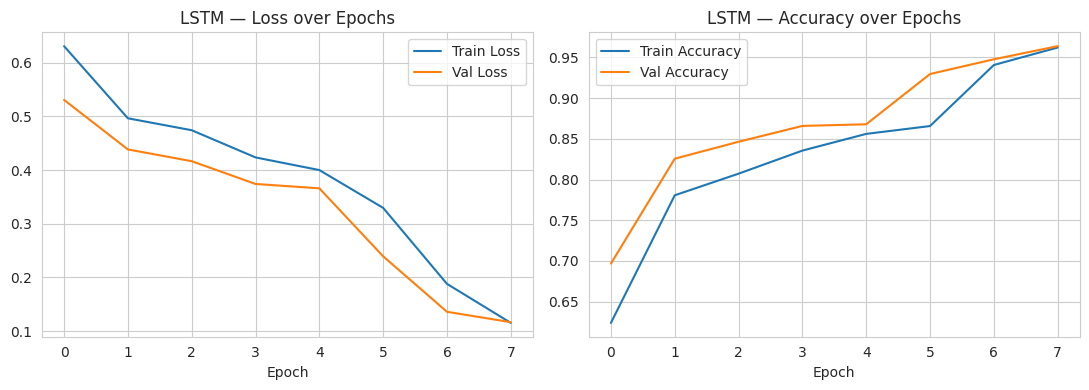

In [ ]:
# Training curves
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(history.history["loss"], label="Train Loss")
axes[0].plot(history.history["val_loss"], label="Val Loss")
axes[0].set_title("LSTM — Loss over Epochs")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["accuracy"], label="Train Accuracy")
axes[1].plot(history.history["val_accuracy"], label="Val Accuracy")
axes[1].set_title("LSTM — Accuracy over Epochs")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()


In [ ]:
# Evaluate the LSTM
lstm_probs = lstm_model.predict(X_test_pad).ravel()
lstm_preds = (lstm_probs >= 0.5).astype(int)

lstm_metrics = {
    "Accuracy": accuracy_score(y_test, lstm_preds),
    "Precision": precision_score(y_test, lstm_preds),
    "Recall": recall_score(y_test, lstm_preds),
    "F1-score": f1_score(y_test, lstm_preds),
}
print("LSTM performance:")
for k, v in lstm_metrics.items():
    print(f"  {k}: {v:.4f}")
print()
print(classification_report(y_test, lstm_preds, target_names=["Safe", "Phishing"]))


117/117 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step
LSTM performance:
  Accuracy: 0.9630
  Precision: 0.9515
  Recall: 0.9541
  F1-score: 0.9528

              precision    recall  f1-score   support

        Safe       0.97      0.97      0.97      2265
    Phishing       0.95      0.95      0.95      1461

    accuracy                           0.96      3726
   macro avg       0.96      0.96      0.96      3726
weighted avg       0.96      0.96      0.96      3726



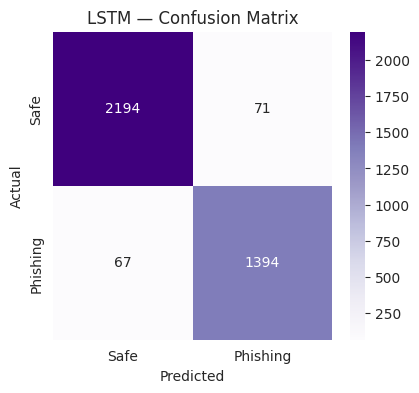

In [ ]:
# LSTM - Confusion Matrix
cm_lstm = confusion_matrix(y_test, lstm_preds)
plt.figure(figsize=(4.5, 4))
sns.heatmap(cm_lstm, annot=True, fmt="d", cmap="Purples",
            xticklabels=["Safe", "Phishing"], yticklabels=["Safe", "Phishing"])
plt.title("LSTM — Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


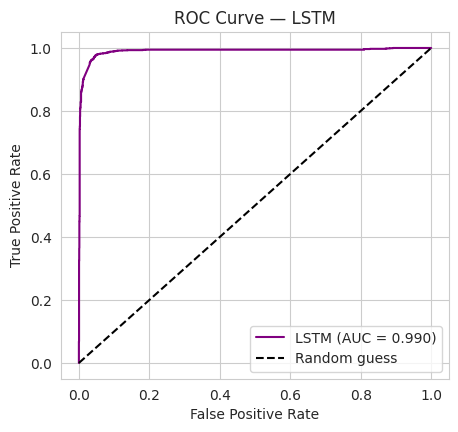

In [ ]:
# LSTM - ROC Curve
fpr_lstm, tpr_lstm, _ = roc_curve(y_test, lstm_probs)
roc_auc_lstm = auc(fpr_lstm, tpr_lstm)

plt.figure(figsize=(5, 4.5))
plt.plot(fpr_lstm, tpr_lstm, label=f"LSTM (AUC = {roc_auc_lstm:.3f})", color="purple")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — LSTM")
plt.legend(loc="lower right")
plt.show()


## Model Comparison

                     Accuracy  Precision  Recall  F1-score
Logistic Regression     0.967     0.9407  0.9774    0.9587
LSTM                    0.963     0.9515  0.9541    0.9528


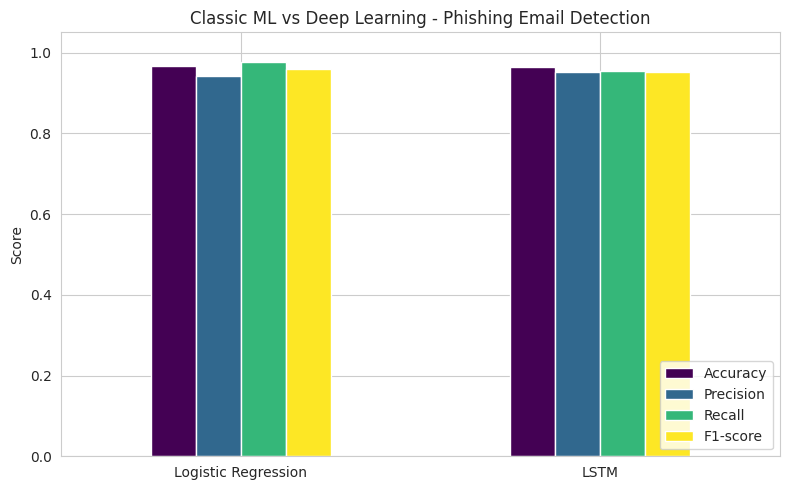

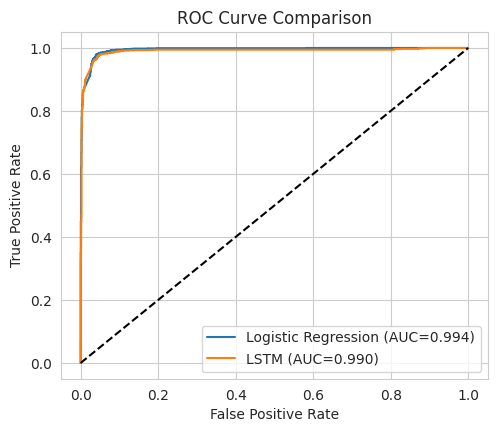

In [ ]:
# Side-by-side comparison table + chart
comparison = pd.DataFrame({
    "Logistic Regression": lr_metrics,
    "LSTM": lstm_metrics,
}).T

print(comparison.round(4))

comparison.plot(kind="bar", figsize=(8, 5), colormap="viridis")
plt.title("Classic ML vs Deep Learning - Phishing Email Detection")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Combined ROC comparison
plt.figure(figsize=(5.5, 4.5))
plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC={roc_auc_lr:.3f})")
plt.plot(fpr_lstm, tpr_lstm, label=f"LSTM (AUC={roc_auc_lstm:.3f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend(loc="lower right")
plt.show()
